# 03 · Road-graph construction

**Objective.** Build, validate and save the sensor graph that the graph model will use, and keep one **canonical sensor order**
that every other array in the project must obey.

**Four different things that must not be confused**

| Concept | Source | What it tells us |
|---|---|---|
| Geographic **coordinates** | `graph_sensor_locations.csv` | where a sensor is on the map; *not* whether sensors are connected |
| Road-network **distance** | `distances_la_2012.csv` | pre-computed **directed** driving distance (metres) from sensor *i* to sensor *j* |
| Binary **connectivity** | derived: `A[i, j] > 0` | a directed edge *i -> j* |
| Weighted **adjacency** | derived from distance | `A = exp(-(d/sigma)^2)`, zero below 0.1 (DCRNN's thresholded Gaussian kernel) |

**Methodology.**
1. Inspect the three graph files (real schemas, no assumptions).
2. Align sensors **by id** with the traffic data and report every discrepancy.
3. Build the adjacency with DCRNN's construction and validate it (shape, diagonal, weights, edges, isolation, symmetry, connectivity).
4. Show that geographic proximity is not road connectivity.
5. Visualise; save the validated graph and a fingerprint of the sensor order.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, visualization as viz

viz.apply_style()
dl.require_raw_files()
clean = dl.load_clean_traffic()          # written by notebook 02
traffic_ids = clean.sensor_ids
print(f"canonical traffic sensors: {len(traffic_ids)}   first ids: {traffic_ids[:4]}")

canonical traffic sensors: 207   first ids: ['773869', '767541', '767542', '717447']


## 1 · Inspect the graph metadata files

In [3]:
locations = dl.load_sensor_locations()
graph_ids = dl.load_sensor_ids_txt()
distances = dl.load_distance_table()

print("graph_sensor_locations.csv:", locations.shape, "| columns:", list(locations.columns), "| dtypes:", dict(locations.dtypes.astype(str)))
display(locations.head(3))
print(f"  latitude  range: {locations.latitude.min():.4f} .. {locations.latitude.max():.4f}")
print(f"  longitude range: {locations.longitude.min():.4f} .. {locations.longitude.max():.4f}")
print(f"\ngraph_sensor_ids.txt: {len(graph_ids)} comma-separated ids, e.g. {graph_ids[:4]}")
print(f"\ndistances_la_2012.csv: {distances.shape} | columns {list(distances.columns)}")
display(distances.head(3))
all_ids_in_distance_file = set(distances['from']) | set(distances['to'])
print(f"  the file covers {len(all_ids_in_distance_file):,} distinct sensors (all LA sensors, not just our {len(traffic_ids)})")
print(f"  distance units: metres (cost). min {distances.cost.min():.0f}  median {distances.cost.median():.0f}  max {distances.cost.max():.0f}")
print(f"  self-pairs (from == to, cost 0): {(distances['from'] == distances['to']).sum():,} | duplicated (from,to) pairs: {distances.duplicated(['from', 'to']).sum()}")
in_subset = distances['from'].isin(traffic_ids) & distances['to'].isin(traffic_ids)
print(f"  rows with both endpoints among our sensors: {in_subset.sum():,} of {len(distances):,}")

graph_sensor_locations.csv: (207, 4) | columns: ['index', 'sensor_id', 'latitude', 'longitude'] | dtypes: {'index': 'int64', 'sensor_id': 'str', 'latitude': 'float64', 'longitude': 'float64'}


,index,sensor_id,latitude,longitude
0,0,773869,34.15497,-118.31829
1,1,767541,34.11621,-118.23799
2,2,767542,34.11641,-118.23819


  latitude  range: 34.0430 .. 34.2216
  longitude range: -118.5368 .. -118.1829

graph_sensor_ids.txt: 207 comma-separated ids, e.g. ['773869', '767541', '767542', '717447']

distances_la_2012.csv: (295374, 3) | columns ['from', 'to', 'cost']


,from,to,cost
0,1201054,1201054,0.0
1,1201054,1201066,2610.9
2,1201054,1201076,2822.7


  the file covers 4,106 distinct sensors (all LA sensors, not just our 207)
  distance units: metres (cost). min 0  median 7730  max 21255
  self-pairs (from == to, cost 0): 4,106 | duplicated (from,to) pairs: 0


  rows with both endpoints among our sensors: 11,753 of 295,374


**How DCRNN builds the adjacency** (read from `scripts/gen_adj_mx.py` in the original repository, which is not vendored here):

1. Create an `N x N` float32 matrix filled with `inf`; map each sensor id to its index in `graph_sensor_ids.txt`.
2. For each row `(from, to, cost)` whose two ids are in the sensor list, set `dist[from, to] = cost` (**one direction only; the
   symmetrisation line is commented out**, so the graph is directed).
3. `sigma` = standard deviation of all *finite* entries of `dist`.
4. `A = exp(-(dist / sigma)^2)`; entries below `normalized_k = 0.1` are set to 0.

We reproduce exactly that in `graph_utils.build_adjacency_from_distances`. We deliberately do **not** unpickle the shipped
`adj_mx.pkl` (pickle files can execute code); rebuilding from the CSV is transparent and testable.

## 2 · Sensor alignment (by id, never by row position)

The canonical order is the column order of the traffic file. `validate_sensor_alignment` matches locations to traffic sensors
*by id*, reports sensors without a location and ids unknown to the traffic data, and raises on duplicates or on any traffic
sensor missing from the graph id list.

In [4]:
ordered_locations, report = gu.validate_sensor_alignment(traffic_ids, locations, graph_ids)
display(pd.Series({k: (v if not isinstance(v, list) else (len(v) if v else 0)) for k, v in report.items()}, name="value").to_frame())
print("traffic sensors without a location record:", report["traffic_without_location"])
print("location records without traffic data     :", report["location_without_traffic"])
print("graph ids not in traffic / traffic ids not in graph:", report["graph_not_in_traffic"], "/", report["traffic_not_in_graph"])
print("duplicate ids (traffic / locations / graph):", report["duplicate_traffic_ids"], report["duplicate_location_ids"], report["duplicate_graph_ids"])

assert list(ordered_locations["sensor_id"]) == traffic_ids                   # node k <-> traffic column k
assert {"node", "sensor_id", "latitude", "longitude"} <= set(ordered_locations.columns) and ordered_locations["node"].is_monotonic_increasing
SENSOR_HASH = gu.sensor_order_hash(traffic_ids)
print("sensor-order fingerprint:", SENSOR_HASH)
display(ordered_locations.head(3))

,value
n_traffic,207
n_locations,207
n_graph_ids,207
duplicate_traffic_ids,0
duplicate_location_ids,0
duplicate_graph_ids,0
traffic_without_location,0
location_without_traffic,0
traffic_not_in_graph,0
graph_not_in_traffic,0


traffic sensors without a location record: []
location records without traffic data     : []
graph ids not in traffic / traffic ids not in graph: [] / []
duplicate ids (traffic / locations / graph): [] [] []
sensor-order fingerprint: 2a38ef551082d02d


,node,sensor_id,index,latitude,longitude
0,0,773869,0,34.15497,-118.31829
1,1,767541,1,34.11621,-118.23799
2,2,767542,2,34.11641,-118.23819


**Interpretation.** All 207 sensors in the traffic file have exactly one location record, the graph id list is the same set in
the same order, and there are no duplicates or unknown ids. Here the location file happens to be in the same row order as the
traffic file, but the code does not rely on that: it matched by id, so a reordered file would be handled correctly (this is
covered by `tests/test_graph.py`).

## 3 · Adjacency construction and validation

In [5]:
adj, road_dist, build_report = gu.build_adjacency_from_distances(distances, traffic_ids, normalized_k=config.GRAPH_NORMALIZED_K)
print(pd.Series(gu.report_to_dict(build_report), name="value").to_frame().to_string())
stats = gu.graph_stats(adj)
scalar_stats = {k: v for k, v in stats.items() if k not in ("in_degree", "out_degree", "isolated_nodes")}
display(pd.Series(scalar_stats, name="value").to_frame())
print("isolated nodes (no edge in or out, ignoring self-loop):", stats["isolated_nodes"], [traffic_ids[i] for i in stats["isolated_nodes"]])

                                       value
n_nodes                           207.000000
n_distance_rows                295374.000000
n_rows_used                     11753.000000
n_rows_skipped_unknown_sensor  283621.000000
n_duplicate_pairs                   0.000000
n_finite_pairs                  11753.000000
sigma_m                          2584.450195
normalized_k                        0.100000


,value
n_nodes,207
shape,"(207, 207)"
n_nonzero_total,1722
n_self_loops,207
n_edges_directed,1515
edge_density,0.035528
weight_min,0.100084
weight_max,0.999832
weight_mean,0.401044
n_reciprocal_edges,404


isolated nodes (no edge in or out, ignoring self-loop): [26] ['717804']


In [6]:
# --- validation checks (each one is asserted) --------------------------------------------------
N = len(traffic_ids)
assert adj.shape == (N, N), "adjacency must be N x N in canonical sensor order"
assert adj.dtype == np.float32 and np.isfinite(adj).all()
assert stats["n_self_loops"] == N and np.all(np.diag(adj) == 1.0), "d_ii = 0 gives weight exp(0) = 1 on the diagonal"
nonzero = adj[adj > 0]
assert nonzero.min() >= config.GRAPH_NORMALIZED_K - 1e-6 and nonzero.max() <= 1.0, "weights must lie in [normalized_k, 1]"
assert (adj >= 0).all()
assert build_report.n_duplicate_pairs == 0
# the weight really is the thresholded Gaussian kernel of the road distance
i, j = np.argwhere((adj > 0) & ~np.eye(N, dtype=bool))[0]
assert np.isclose(adj[i, j], np.exp(-(road_dist[i, j] / build_report.sigma_m) ** 2), rtol=1e-4)
# pairs without a listed road distance have no edge
assert np.all(adj[np.isinf(road_dist)] == 0)

print(f"matrix {adj.shape} | self-loops {stats['n_self_loops']} | directed edges (off-diagonal) {stats['n_edges_directed']} | total non-zeros {stats['n_nonzero_total']}")
print(f"weights of edges: min {stats['weight_min']:.3f}  mean {stats['weight_mean']:.3f}  max {stats['weight_max']:.3f}  (sigma = {build_report.sigma_m:.0f} m, cut-off k = {build_report.normalized_k})")
print(f"symmetric? {stats['is_symmetric']} (max |A - A^T| = {stats['max_asymmetry']:.3f}); reciprocal edges: {stats['n_reciprocal_edges']} of {stats['n_edges_directed']} = {stats['reciprocal_fraction']:.1%}")
print(f"degree (excluding self): in {stats['in_degree'].mean():.1f} avg / max {stats['max_in_degree']}; out {stats['out_degree'].mean():.1f} avg / max {stats['max_out_degree']}")
print(f"weakly connected components: {stats['n_weak_components']} (largest has {stats['largest_weak_component']} sensors); strongly connected components: {stats['n_strong_components']}")
print("all graph validation checks passed")

matrix (207, 207) | self-loops 207 | directed edges (off-diagonal) 1515 | total non-zeros 1722
weights of edges: min 0.100  mean 0.401  max 1.000  (sigma = 2584 m, cut-off k = 0.1)
symmetric? False (max |A - A^T| = 0.996); reciprocal edges: 404 of 1515 = 26.7%
degree (excluding self): in 7.3 avg / max 17; out 7.3 avg / max 18
weakly connected components: 2 (largest has 206 sensors); strongly connected components: 13
all graph validation checks passed


**Interpretation.**

* **Dimensions and order:** `207 x 207`, rows/columns in canonical sensor order. Row `i` is the *source* sensor, column `j` the *target*: `A[i, j] > 0` is an edge `i -> j`.
* **Self-loops:** every diagonal entry is exactly 1 (a sensor is at distance 0 from itself). The graph model adds a self-loop to every attention neighbourhood anyway.
* **Directed:** the matrix is **not** symmetric, and only about a quarter of the edges are reciprocal (the printed fraction), which is plausible for directional highway data. We therefore do **not** symmetrise: the graph model attends separately over each node's *in-edge* and *out-edge* neighbours.
* **Sparse:** each sensor has only a handful of neighbours, and one sensor has none (isolated): for it the graph model reduces to its own temporal features.
* **Plausibility check (not a proof):** the total count of non-zero entries (1,722, including the 207 self-loops) equals the figure commonly quoted for DCRNN's METR-LA graph. We did not unpickle the original `adj_mx.pkl`, so we cannot claim bit-wise identity.

## 4 · Geographic proximity is not road connectivity

Straight-line (haversine) distance between sensor coordinates is only a diagnostic. We compare it with the road-network graph.

sensor pairs closer than 1 km in a straight line: 417 (unordered pairs)
  ...of which have NO edge in either direction of the road graph: 66 (16%)
directed edges whose endpoints are > 5 km apart in a straight line: 0
road distance / straight-line distance over the 1515 edges: median 1.22, 5th pct 1.00, 95th pct 32.83


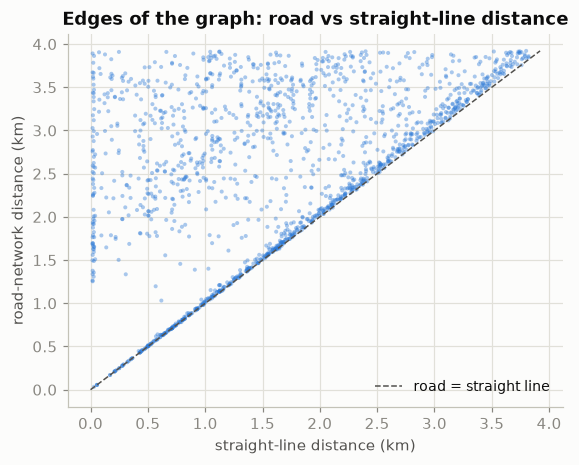

In [7]:
geo = gu.haversine_matrix(ordered_locations["latitude"].to_numpy(), ordered_locations["longitude"].to_numpy())
off = ~np.eye(N, dtype=bool)
edge = (adj > 0) & off

near = (geo < 1000) & off
n_near, n_near_unlinked = int(near.sum() // 2), int((near & ~edge & ~edge.T).sum() // 2)
print(f"sensor pairs closer than 1 km in a straight line: {n_near} (unordered pairs)")
print(f"  ...of which have NO edge in either direction of the road graph: {n_near_unlinked} ({n_near_unlinked / n_near:.0%})")
assert n_near_unlinked > 0, "expected at least some close-by pairs without a road edge"
print(f"directed edges whose endpoints are > 5 km apart in a straight line: {int((edge & (geo > 5000)).sum())}")

both = edge & np.isfinite(road_dist)
ratio = road_dist[both] / np.maximum(geo[both], 1.0)
print(f"road distance / straight-line distance over the {both.sum()} edges: median {np.median(ratio):.2f}, "
      f"5th pct {np.percentile(ratio, 5):.2f}, 95th pct {np.percentile(ratio, 95):.2f}")

fig, ax = plt.subplots(figsize=(5.8, 4.4))
ax.scatter(geo[both] / 1000, road_dist[both] / 1000, s=7, alpha=0.4, color="#2a78d6", edgecolor="none")
lim = max(geo[both].max(), road_dist[both].max()) / 1000
ax.plot([0, lim], [0, lim], color=viz.INK_2, lw=1, ls="--", label="road = straight line")
ax.set_xlabel("straight-line distance (km)"); ax.set_ylabel("road-network distance (km)")
ax.set_title("Edges of the graph: road vs straight-line distance"); ax.legend(); viz.save_figure(fig, "03_road_vs_geographic_distance"); plt.show()

**Interpretation.** Most pairs that are within 1 km of each other do have a road edge, but a non-trivial share (printed above) have
none in either direction, so a coordinate-radius graph would add connections that the road network does not support. Road distance
is also never shorter than the straight line and is typically somewhat longer (median ratio printed above), with a long tail of edges
whose road distance is many times the straight-line distance (close by on the map, far apart by road). We therefore use the
**road-distance graph** and use the coordinates **only** for maps and as static descriptors.

## 5 · Visualisation

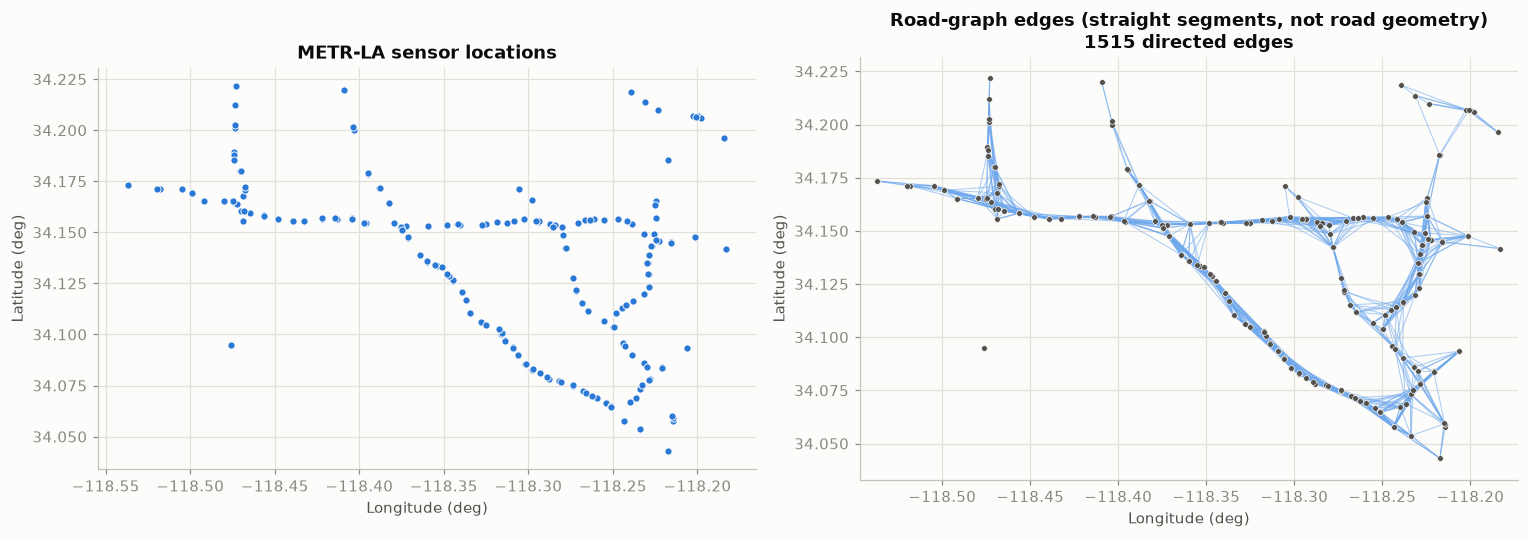

drawn edges: 1515 of 1515


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
viz.plot_sensor_locations(axes[0], ordered_locations)
n_drawn = viz.plot_graph_on_map(axes[1], ordered_locations, adj, max_edges=None, title="Road-graph edges (straight segments, not road geometry)")
fig.tight_layout(); viz.save_figure(fig, "03_sensor_locations_and_graph"); plt.show()
print(f"drawn edges: {n_drawn} of {stats['n_edges_directed']}")

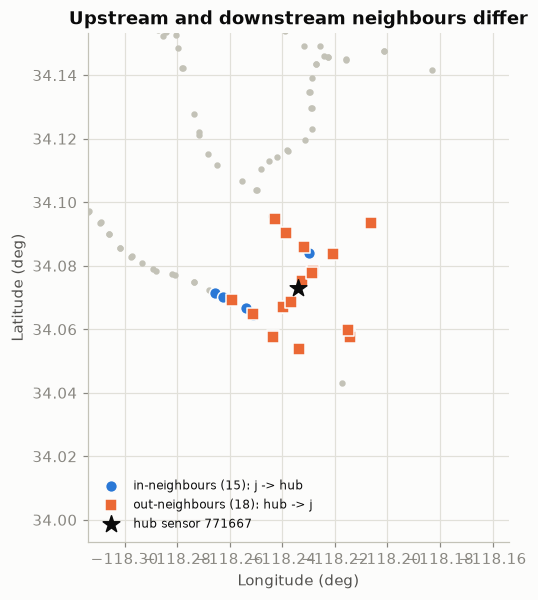

hub has 15 in-neighbours and 18 out-neighbours; 8 sensors are both


In [9]:
# Directedness made visible: the neighbourhood of the sensor with the most connections
deg_total = stats["in_degree"] + stats["out_degree"]
hub = int(np.argmax(deg_total))
in_nb, out_nb = np.flatnonzero(edge[:, hub]), np.flatnonzero(edge[hub, :])
lon, lat = ordered_locations["longitude"].to_numpy(), ordered_locations["latitude"].to_numpy()
fig, ax = plt.subplots(figsize=(7.2, 6))
ax.scatter(lon, lat, s=10, color="#c3c2b7", zorder=2)
ax.scatter(lon[in_nb], lat[in_nb], s=60, color="#2a78d6", edgecolor=viz.SURFACE, zorder=3, label=f"in-neighbours ({len(in_nb)}): j -> hub")
ax.scatter(lon[out_nb], lat[out_nb], s=60, marker="s", color="#eb6834", edgecolor=viz.SURFACE, zorder=3, label=f"out-neighbours ({len(out_nb)}): hub -> j")
ax.scatter(lon[hub], lat[hub], s=130, marker="*", color=viz.INK, zorder=4, label=f"hub sensor {traffic_ids[hub]}")
pad = 0.08
ax.set_xlim(lon[hub] - pad, lon[hub] + pad); ax.set_ylim(lat[hub] - pad, lat[hub] + pad)
ax.set_aspect(1.0 / np.cos(np.deg2rad(lat.mean()))); ax.set_xlabel("Longitude (deg)"); ax.set_ylabel("Latitude (deg)")
ax.set_title("Upstream and downstream neighbours differ"); ax.legend(loc="lower left", fontsize=8)
viz.save_figure(fig, "03_hub_neighbourhood"); plt.show()
both_dirs = np.intersect1d(in_nb, out_nb)
print(f"hub has {len(in_nb)} in-neighbours and {len(out_nb)} out-neighbours; {len(both_dirs)} sensors are both")

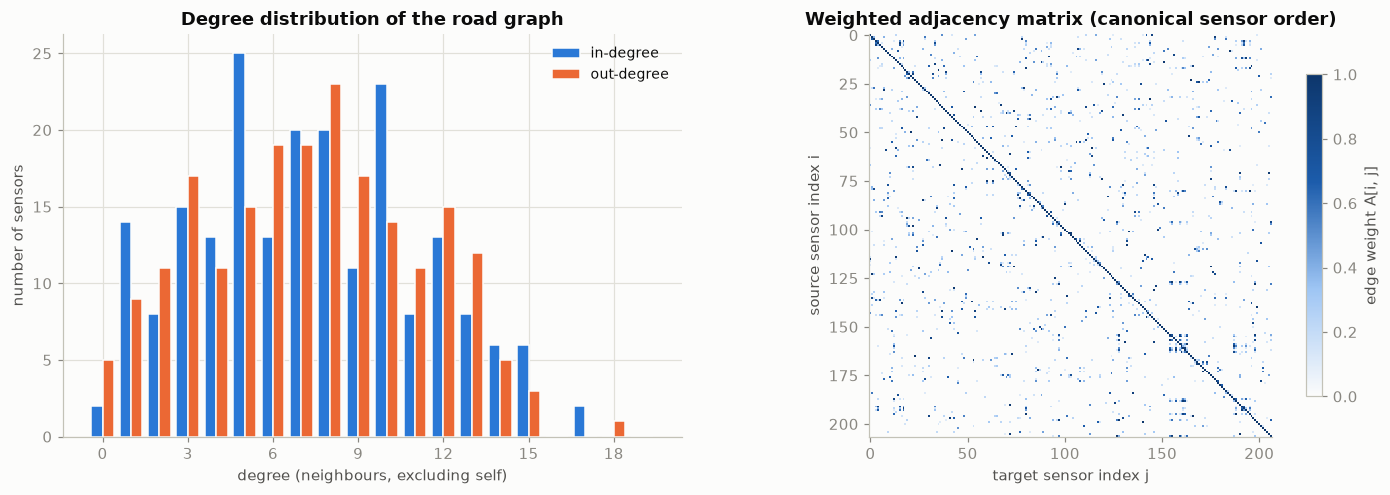

,value
measure,
sensors,207.00
directed edges (excl. self),1515.00
reciprocal edges,404.00
mean in-degree,7.32
max in-degree,17.00
max out-degree,18.00
isolated sensors,1.00
weakly connected components,2.00
largest weak component,206.00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
viz.plot_degree_distribution(axes[0], stats["in_degree"], stats["out_degree"])
viz.plot_adjacency_heatmap(axes[1], adj, title="Weighted adjacency matrix (canonical sensor order)")
fig.tight_layout(); viz.save_figure(fig, "03_degree_and_adjacency"); plt.show()

connectivity = pd.DataFrame({
    "measure": ["sensors", "directed edges (excl. self)", "reciprocal edges", "mean in-degree", "max in-degree", "max out-degree",
                "isolated sensors", "weakly connected components", "largest weak component", "strongly connected components"],
    "value": [N, stats["n_edges_directed"], stats["n_reciprocal_edges"], round(stats["in_degree"].mean(), 2), stats["max_in_degree"],
              stats["max_out_degree"], len(stats["isolated_nodes"]), stats["n_weak_components"], stats["largest_weak_component"], stats["n_strong_components"]],
}).set_index("measure")
display(connectivity)

**Interpretation.** The graph is sparse: in- and out-degrees are small and similarly distributed. In the adjacency heatmap the
self-loop diagonal is the only clear structure; the remaining edges are scattered across the whole matrix with a few dense
clusters, i.e. the sensor-id order carries no spatial locality and any model must use the matrix itself rather than index
proximity. The graph is one weakly connected component of 206 sensors plus the isolated sensor, but it splits into many strongly
connected components because edges are directed. For a 2-block graph network this means information can reach a sensor from
neighbours up to two hops away, not from the whole network.

## 6 · Save the validated graph and lock the sensor order

Everything downstream loads these files through `graph_utils.load_graph_artifacts(expected_sensor_ids=...)`, which compares the
fingerprint of the saved order with the order of the traffic tensor and **raises** if they ever differ.

In [11]:
meta = {
    "source": "DCRNN thresholded Gaussian kernel on directed road distances (distances_la_2012.csv)",
    "normalized_k": config.GRAPH_NORMALIZED_K, "sigma_m": build_report.sigma_m,
    "n_edges_directed": stats["n_edges_directed"], "n_self_loops": stats["n_self_loops"], "directed": True,
    "reciprocal_fraction": stats["reciprocal_fraction"], "isolated_nodes": stats["isolated_nodes"],
    "n_weak_components": stats["n_weak_components"], "n_strong_components": stats["n_strong_components"],
    "distance_units": "metres", "adjacency_convention": "A[i, j] > 0 means edge i -> j",
    "sensor_ids_source": "column order of metr-la.h5",
}
gu.save_graph_artifacts(adj, road_dist, ordered_locations, meta)

art = gu.load_graph_artifacts(expected_sensor_ids=traffic_ids)       # raises AlignmentError on any order mismatch
assert np.array_equal(art.adjacency, adj) and art.sensor_ids == traffic_ids
print("saved:", [p.name for p in (config.ADJACENCY_NPY, config.DISTANCE_MATRIX_NPY, config.SENSOR_ORDER_CSV, config.GRAPH_META_JSON)])
print("fingerprint in graph_meta.json:", art.meta["sensor_order_hash"], "== traffic order:", gu.sensor_order_hash(traffic_ids))

# the guard really fires: a shuffled order is rejected
try:
    gu.load_graph_artifacts(expected_sensor_ids=traffic_ids[::-1])
    raise SystemExit("guard failed to fire")
except gu.AlignmentError as err:
    print("order guard works ->", str(err)[:90], "...")
print("\nGraph construction complete. Next: 04_baseline_models.ipynb")

saved: ['adjacency.npy', 'road_distance_matrix.npy', 'sensor_order.csv', 'graph_meta.json']
fingerprint in graph_meta.json: 2a38ef551082d02d == traffic order: 2a38ef551082d02d
order guard works -> Sensor order changed in traffic data vs saved graph: hash c3761653b5038453 != canonical 2a ...

Graph construction complete. Next: 04_baseline_models.ipynb
